In [2]:
   !pip install -q ultralytics opencv-python pandas matplotlib seaborn pyyaml

import torch
import ultralytics

print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not available. Enable GPU in Runtime settings.")



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch version: 2.14.1+cu130
Ultralytics version: 8.4.210
GPU available: Tesla T4


In [12]:

import os
import zipfile
import shutil
import random
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter, defaultdict
from ultralytics import YOLO
from IPython.display import display
from google.colab import drive


random.seed(42)
np.random.seed(42)


drive.mount("/content/drive")

ZIP_PATH = Path(
    "/content/drive/MyDrive/pcb defect detection.v2i.yolov8.zip"
)

BASE_DIR = Path("/content/drive/MyDrive/pcb defect detection.v2i.yolov8.zip")


EXTRACT_DIR = Path("/content/pcb_dataset")
print("Drive connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive connected successfully!


In [13]:

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Dataset ZIP not found: {ZIP_PATH}"
    )

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if not any(EXTRACT_DIR.iterdir()):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

print("Dataset extraction completed!")


Dataset extraction completed!


In [14]:
def show_directory_structure(root, max_depth=3):

    root = Path(root)

    for current, dirs, files in os.walk(root):

        depth = len(Path(current).relative_to(root).parts)

        if depth > max_depth:
            dirs[:] = []
            continue

        print("  " * depth + Path(current).name + "/")

        for file in files[:5]:
            print("  " * (depth + 1) + file)

show_directory_structure(EXTRACT_DIR)


pcb_dataset/
  README.roboflow.txt
  README.dataset.txt
  data.yaml
  valid/
    images/
      01_spur_02_jpg.rf.d9006706365f21f73ce753eac81991a7.jpg
      11_mouse_bite_05_jpg.rf.789f490d7f1c8a69be98ed2514d3e5d4.jpg
      08_open_circuit_02_jpg.rf.69ad6424c0242024b1a9f31470cad47b.jpg
      05_spurious_copper_06_jpg.rf.2895d883cc706db94227128074ba12af.jpg
      05_short_01_jpg.rf.003b1a028cc611d9d7db8ec5f3627918.jpg
    labels/
      11_spur_01_jpg.rf.1e5255ba25a75867509d1fc874e571f9.txt
      04_short_10_jpg.rf.4a5b2fb9c9ee3de8f6ce2e7d09d587a4.txt
      08_missing_hole_06_jpg.rf.a3fb78652e94e55afe94e0cc6629edbc.txt
      05_spurious_copper_06_jpg.rf.2895d883cc706db94227128074ba12af.txt
      11_spur_07_jpg.rf.07d2c02150c54721691f73a1bfa60747.txt
  train/
    images/
      09_spur_07_jpg.rf.7d4612a6787d178799aa17e31534eb10.jpg
      04_spur_20_jpg.rf.96c274e1f4efc9a584f12e5d025a0878.jpg
      01_spur_09_jpg.rf.e5f5ece78ffbc1baa8fb445392aff5f9.jpg
      10_short_03_jpg.rf.032a927648ef64

In [25]:
import yaml
from pathlib import Path

# Find YAML files inside the extracted dataset
yaml_files = sorted(
    list(EXTRACT_DIR.rglob("*.yaml")) + list(EXTRACT_DIR.rglob("*.yml"))
)
print("YAML files found:", [str(p) for p in yaml_files])

if not yaml_files:
    raise FileNotFoundError(f"No YAML files found in {EXTRACT_DIR}")

# Find the actual dataset root
DATASET_ROOT = None
DATA_YAML_PATH = None

for yaml_file in yaml_files:

    parent = yaml_file.parent

    train_dir = parent / "train" / "images"

    val_dir = parent / "valid" / "images"
    if not val_dir.exists():
        val_dir = parent / "val" / "images"

    if train_dir.exists() and val_dir.exists():
        DATASET_ROOT = parent
        DATA_YAML_PATH = yaml_file
        break

if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Could not identify train/images and valid/images. "
        "Check the directory structure printed in the previous cell and adjust paths."
    )
VAL_FOLDER = (
    "valid" if (DATASET_ROOT / "valid" / "images").exists()
    else "val"
)

# Read original configuration
with open(DATA_YAML_PATH, "r") as f:
    data_config = yaml.safe_load(f)

# Construct corrected configuration
data_config["path"] = str(DATASET_ROOT)
data_config["train"] = "train/images"
data_config["val"] = f"{VAL_FOLDER}/images"

if (DATASET_ROOT / "test" / "images").exists():
    data_config["test"] = "test/images"

# Verify six classes
if "names" not in data_config:
    raise ValueError("Class names missing from data.yaml")

names = data_config["names"]

if isinstance(names, dict):
    CLASS_NAMES = {
        int(k): v for k, v in names.items()
    }
else:
    CLASS_NAMES = dict(enumerate(names))

if len(CLASS_NAMES) != 6:
    raise ValueError(
        f"Expected 6 classes, found {len(CLASS_NAMES)}"
    )

print("Dataset root:", DATASET_ROOT)
print("Validation folder:", VAL_FOLDER)
print("Classes:", CLASS_NAMES)

# Save corrected configuration
FIXED_YAML = Path("/content/pcb_data.yaml")

with open(FIXED_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("\nCorrected YAML:")
print(FIXED_YAML.read_text())




YAML files found: ['/content/pcb_dataset/data.yaml']
Dataset root: /content/pcb_dataset
Validation folder: valid
Classes: {0: 'missing_hole', 1: 'mouse_bite', 2: 'open_circuit', 3: 'short', 4: 'spur', 5: 'spurious_copper'}

Corrected YAML:
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- missing_hole
- mouse_bite
- open_circuit
- short
- spur
- spurious_copper
roboflow:
  workspace: uthm-project-visionbased-pcb-defect-detection
  project: pcb-defect-detection-9ewqw-duvuw
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/uthm-project-visionbased-pcb-defect-detection/pcb-defect-detection-9ewqw-duvuw/dataset/2
path: /content/pcb_dataset



In [15]:

yaml_files = list(EXTRACT_DIR.rglob("data.yaml"))

if not yaml_files:
    raise FileNotFoundError(
        "No data.yaml found in extracted dataset."
    )

print("Configuration files found:")

for file in yaml_files:
    print(file)

DATA_YAML_PATH = yaml_files[0]

with open(DATA_YAML_PATH, "r") as f:
    data_config = yaml.safe_load(f)

print("\nOriginal dataset configuration:")
print(yaml.safe_dump(data_config, sort_keys=False))


Configuration files found:
/content/pcb_dataset/data.yaml

Original dataset configuration:
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 6
names:
- missing_hole
- mouse_bite
- open_circuit
- short
- spur
- spurious_copper
roboflow:
  workspace: uthm-project-visionbased-pcb-defect-detection
  project: pcb-defect-detection-9ewqw-duvuw
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/uthm-project-visionbased-pcb-defect-detection/pcb-defect-detection-9ewqw-duvuw/dataset/2



In [17]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Make sure VAL_FOLDER exists even if the earlier cell wasn't run
VAL_FOLDER = "valid" if (DATASET_ROOT / "valid" / "images").exists() else "val"

SPLITS = {
    "train": "train",
    "validation": VAL_FOLDER,
    "test": "test"
}

split_counts = {}

for split_name, folder_name in SPLITS.items():

    image_dir = DATASET_ROOT / folder_name / "images"
    label_dir = DATASET_ROOT / folder_name / "labels"

    if not image_dir.exists():
        print(f"{split_name}: folder not available")
        continue

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    # Check image-label pairing by file name
    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    split_counts[split_name] = {
        "images": len(images),
        "annotation_files": len(labels),
        "images_without_labels": len(image_stems - label_stems),
        "labels_without_images": len(label_stems - image_stems)
    }

    print(
        f"{split_name}: "
        f"{len(images)} images, "
        f"{len(labels)} annotation files"
    )

display(pd.DataFrame(split_counts).T)

train: 1880 images, 1880 annotation files
validation: 517 images, 517 annotation files
test: 189 images, 189 annotation files


,images,annotation_files,images_without_labels,labels_without_images
train,1880,1880,0,0
validation,517,517,0,0
test,189,189,0,0


In [19]:
train_label_dir = DATASET_ROOT / "train" / "labels"

if not train_label_dir.exists():
    raise FileNotFoundError(f"Train labels folder not found: {train_label_dir}")

class_counts = Counter()
invalid_annotations = []

with open(DATA_YAML_PATH, "r") as f:
    names = yaml.safe_load(f)["names"]

CLASS_NAMES = (
    {int(k): v for k, v in names.items()}
    if isinstance(names, dict)
    else dict(enumerate(names))
)

for label_file in train_label_dir.glob("*.txt"):

    with open(label_file, "r") as f:

        for line_number, line in enumerate(f, start=1):

            if not line.strip():
                continue

            values = line.split()

            try:
                if len(values) != 5:
                    raise ValueError(f"Expected 5 values, found {len(values)}")

                class_id = int(float(values[0]))
                xc, yc, bw, bh = map(float, values[1:])

                if class_id not in CLASS_NAMES:
                    raise ValueError(f"Unknown class ID: {class_id}")

                if not np.isfinite([xc, yc, bw, bh]).all():
                    raise ValueError("Non-finite coordinate")

                if not (
                    0 <= xc <= 1 and
                    0 <= yc <= 1 and
                    0 < bw <= 1 and
                    0 < bh <= 1
                ):
                    raise ValueError("Invalid normalized box")

                if (
                    xc - bw / 2 < -1e-6 or
                    yc - bh / 2 < -1e-6 or
                    xc + bw / 2 > 1 + 1e-6 or
                    yc + bh / 2 > 1 + 1e-6
                ):
                    raise ValueError("Bounding box outside image")

                class_counts[class_id] += 1

            except Exception as e:

                invalid_annotations.append({
                    "file": label_file.name,
                    "line": line_number,
                    "error": str(e)
                })

total_boxes = sum(class_counts.values())

distribution = pd.DataFrame([
    {
        "class_id": cid,
        "class_name": CLASS_NAMES[cid],
        "instances": class_counts[cid],
        "percentage": round(100 * class_counts[cid] / total_boxes, 2) if total_boxes else 0
    }
    for cid in CLASS_NAMES
])

display(distribution)

print("Total bounding boxes:", total_boxes)
print("Invalid annotations:", len(invalid_annotations))

if invalid_annotations:
    display(pd.DataFrame(invalid_annotations).head(20))

,class_id,class_name,instances,percentage
0,0,missing_hole,1160,14.55
1,1,mouse_bite,1302,16.33
2,2,open_circuit,1341,16.82
3,3,short,1389,17.42
4,4,spur,1423,17.85
5,5,spurious_copper,1359,17.04


Total bounding boxes: 7974
Invalid annotations: 0


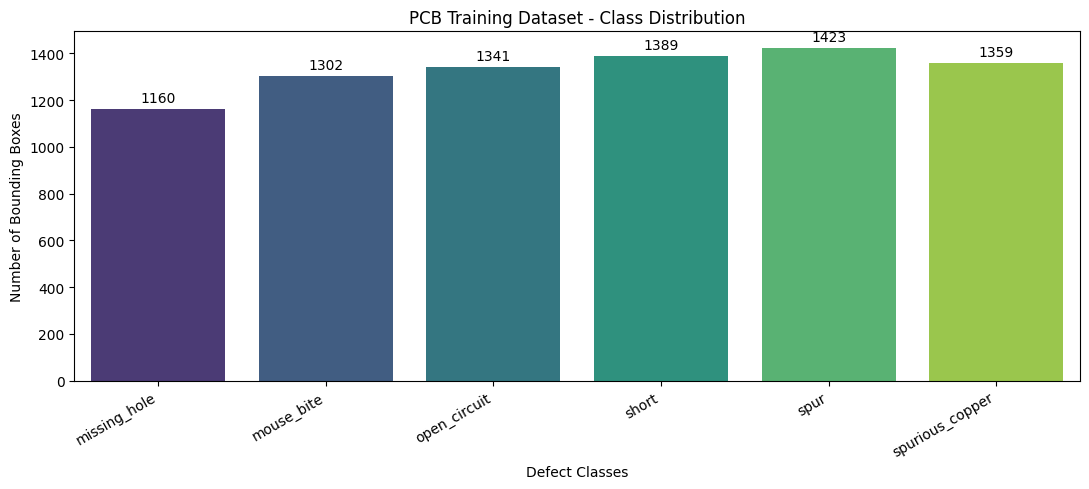

In [20]:
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=distribution,
    x="class_name",
    y="instances",
    hue="class_name",
    palette="viridis",
    legend=False
)

# Show the count on top of each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("PCB Training Dataset - Class Distribution")
plt.xlabel("Defect Classes")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

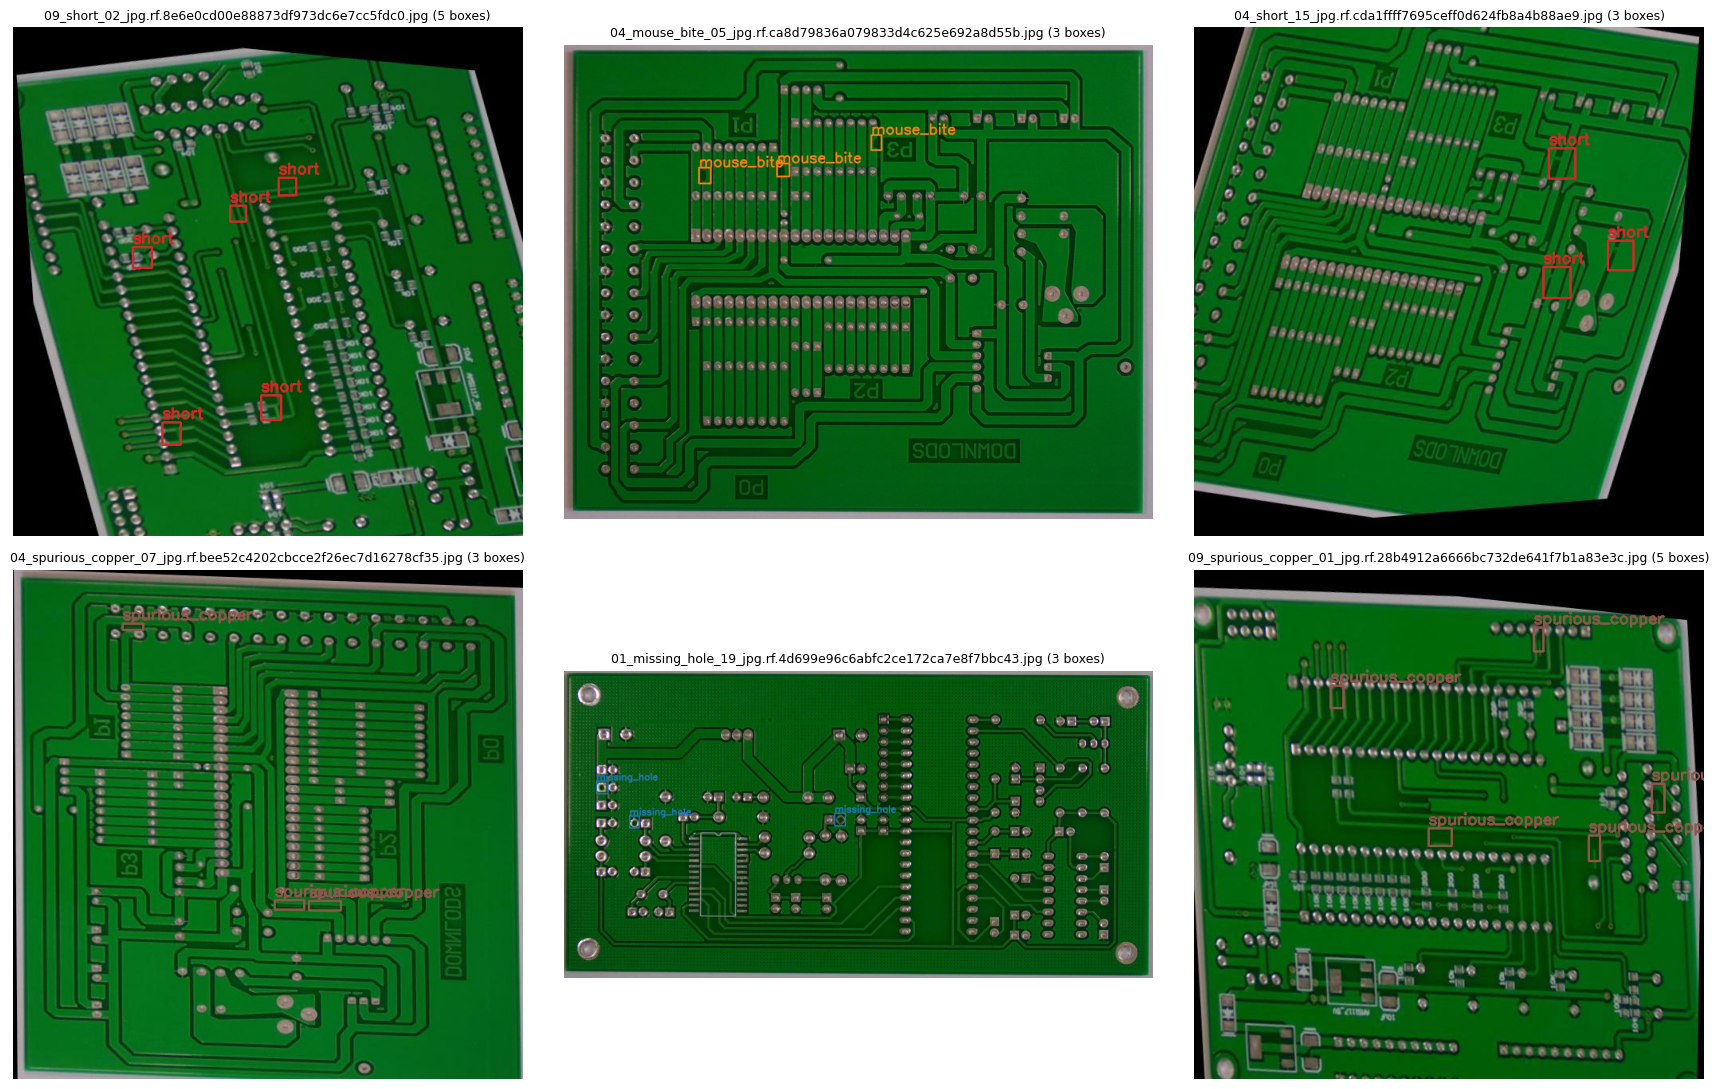

In [21]:
def visualize_annotations(num_images=6):

    image_dir = DATASET_ROOT / "train" / "images"
    label_dir = DATASET_ROOT / "train" / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if not images:
        print("No images found in", image_dir)
        return

    selected = random.sample(images, min(num_images, len(images)))

    # One distinct color per class (RGB, since we convert to RGB before drawing)
    cmap = plt.get_cmap("tab10")
    colors = {
        cid: tuple(int(c * 255) for c in cmap(i % 10)[:3])
        for i, cid in enumerate(sorted(CLASS_NAMES))
    }

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    axes = axes.flatten()

    for ax, image_path in zip(axes, selected):

        image = cv2.imread(str(image_path))

        if image is None:
            ax.axis("off")
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        # Scale line and text size with image resolution
        thickness = max(1, round(min(h, w) / 300))
        font_scale = max(0.4, min(h, w) / 1000)

        label_path = label_dir / f"{image_path.stem}.txt"
        box_count = 0

        if label_path.exists():

            with open(label_path) as f:

                for line in f:

                    values = line.split()

                    if len(values) != 5:
                        continue

                    cid, xc, yc, bw, bh = map(float, values)
                    cid = int(cid)

                    if cid not in CLASS_NAMES:
                        continue

                    x1 = int((xc - bw / 2) * w)
                    y1 = int((yc - bh / 2) * h)
                    x2 = int((xc + bw / 2) * w)
                    y2 = int((yc + bh / 2) * h)

                    color = colors[cid]
                    class_name = CLASS_NAMES[cid]

                    cv2.rectangle(image, (x1, y1), (x2, y2), color, thickness)

                    cv2.putText(
                        image,
                        class_name,
                        (x1, max(15, y1 - 5)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        font_scale,
                        color,
                        thickness
                    )

                    box_count += 1

        ax.imshow(image)
        ax.set_title(f"{image_path.name} ({box_count} boxes)", fontsize=9)
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_annotations(6)

In [22]:
MODEL_NAME = "yolo11s.pt"

model = YOLO(MODEL_NAME)

print("YOLO11s loaded successfully!")


YOLO11s loaded successfully!


In [26]:


TRAIN_CONFIG = {

    # Dataset
    "data": str(FIXED_YAML),

    # Training
    "epochs": 100,
    "imgsz": 640,
    "batch": 16,

    # GPU
    "device": 0,
    "workers": 2,

    # Optimisation
    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.01,
    "weight_decay": 0.0005,
    "cos_lr": True,
    "warmup_epochs": 3,

    # Augmentation
    "degrees": 5,
    "translate": 0.05,
    "scale": 0.2,
    "fliplr": 0.5,
    "flipud": 0.5,
    "mosaic": 1.0,
    "close_mosaic": 10,

    # Training management
    "patience": 20,
    "pretrained": True,
    "seed": 42,
    "deterministic": True,
    "amp": True,

    # Save training results
    "project": "/content/pcb_results",
    "name": "yolo11s_baseline",
    "exist_ok": True,
    "save_period": 10,

    # Visualisation
    "plots": True,
    "save": True,
    "verbose": True
}



In [27]:

results = model.train(**TRAIN_CONFIG)

print("Training completed!")


Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/pcb_data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_baseline, nbs=64, nms=None, opset=None, optimize=False, opt

In [28]:
RUN_DIR = Path(TRAIN_CONFIG["project"]) / TRAIN_CONFIG["name"]

BEST_MODEL_PATH = RUN_DIR / "weights" / "best.pt"
LAST_MODEL_PATH = RUN_DIR / "weights" / "last.pt"

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(f"best.pt was not generated! Checked: {BEST_MODEL_PATH}")

print("Best model:", BEST_MODEL_PATH)
print("Last model:", LAST_MODEL_PATH, "| exists:", LAST_MODEL_PATH.exists())

trained_model = YOLO(str(BEST_MODEL_PATH))

print("Best checkpoint loaded successfully!")

Best model: /content/pcb_results/yolo11s_baseline/weights/best.pt
Last model: /content/pcb_results/yolo11s_baseline/weights/last.pt | exists: True
Best checkpoint loaded successfully!


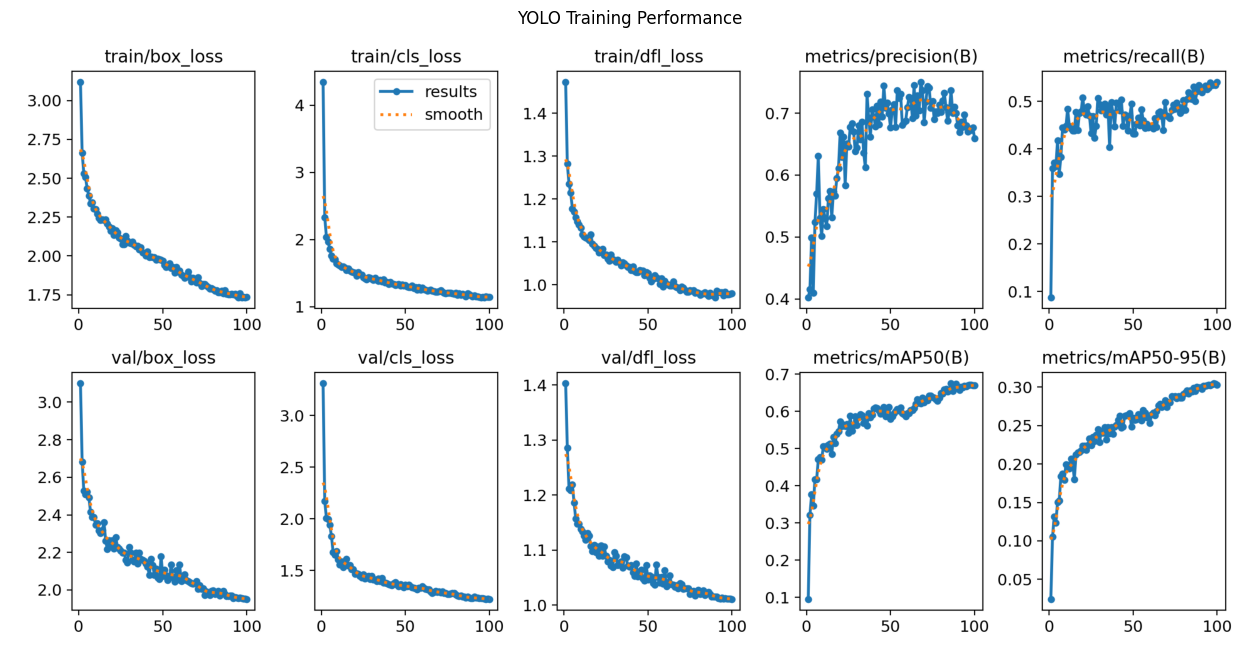

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
95,96,4771.50,1.75780,1.14491,0.98331,0.66998,0.53955,0.66919,0.30238,1.95856,1.23046,1.01218,0.000016,0.000016,0.000016
96,97,4825.01,1.73231,1.13917,0.97775,0.67487,0.53396,0.67069,0.30398,1.95614,1.22924,1.01156,0.000014,0.000014,0.000014
97,98,4878.79,1.73461,1.14996,0.97818,0.67222,0.53497,0.67160,0.30498,1.95374,1.22494,1.01101,0.000012,0.000012,0.000012
98,99,4929.91,1.73154,1.14166,0.97836,0.67635,0.53389,0.66954,0.30435,1.95264,1.22598,1.01099,0.000011,0.000011,0.000011
99,100,4980.20,1.73431,1.14740,0.97970,0.65939,0.54089,0.66915,0.30325,1.95134,1.22421,1.01070,0.000010,0.000010,0.000010


Best epoch: 98 | mAP50: 0.6716 | mAP50-95: 0.3050


In [29]:
results_image = RUN_DIR / "results.png"

if results_image.exists():
    img = cv2.imread(str(results_image))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(16, 9))
    plt.imshow(img)
    plt.axis("off")
    plt.title("YOLO Training Performance")
    plt.show()
else:
    print("results.png not found in", RUN_DIR)

# Inspect the raw metrics
results_csv = RUN_DIR / "results.csv"

if results_csv.exists():
    training_history = pd.read_csv(results_csv)
    training_history.columns = training_history.columns.str.strip()  # YOLO pads column names with spaces
    display(training_history.tail())

    # Best epoch by mAP@0.5:0.95
    best_row = training_history.loc[training_history["metrics/mAP50-95(B)"].idxmax()]
    print(f"Best epoch: {int(best_row['epoch'])} | "
          f"mAP50: {best_row['metrics/mAP50(B)']:.4f} | "
          f"mAP50-95: {best_row['metrics/mAP50-95(B)']:.4f}")
else:
    print("results.csv not found in", RUN_DIR)

In [30]:
val_metrics = trained_model.val(
    data=str(FIXED_YAML),
    split="val",
    imgsz=TRAIN_CONFIG["imgsz"],
    batch=TRAIN_CONFIG["batch"],
    device=TRAIN_CONFIG["device"],
    plots=True,
    verbose=False,
    project=TRAIN_CONFIG["project"],
    name="validation",
    exist_ok=True
)

print("\nVALIDATION RESULTS")
print(f"Precision : {val_metrics.box.mp:.4f}")
print(f"Recall    : {val_metrics.box.mr:.4f}")
print(f"mAP50     : {val_metrics.box.map50:.4f}")
print(f"mAP50-95  : {val_metrics.box.map:.4f}")

# Per-class results (ap_class_index lists the classes that actually appear in the val set)
per_class = pd.DataFrame({
    "class_id": val_metrics.box.ap_class_index,
    "class_name": [CLASS_NAMES[int(i)] for i in val_metrics.box.ap_class_index],
    "precision": val_metrics.box.p,
    "recall": val_metrics.box.r,
    "mAP50": val_metrics.box.ap50,
    "mAP50-95": val_metrics.box.ap
}).round(4)

print("\nPer-class metrics:")
display(per_class)

print("Validation plots saved to:", val_metrics.save_dir)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1756.1±644.6 MB/s, size: 116.6 KB)
val: Scanning /content/pcb_dataset/valid/labels.cache... 517 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 517/517 166.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 2.8it/s 11.6s
                   all        517       2218      0.674      0.539      0.673      0.307
Speed: 1.3ms preprocess, 10.0ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/pcb_results/validation

VALIDATION RESULTS
Precision : 0.6739
Recall    : 0.5391
mAP50     : 0.6733
mAP50-95  : 0.3069

Per-class metrics:


,class_id,class_name,precision,recall,mAP50,mAP50-95
0,0,missing_hole,0.7782,0.6347,0.7914,0.4236
1,1,mouse_bite,0.6993,0.5305,0.6696,0.3062
2,2,open_circuit,0.6935,0.3611,0.5568,0.2168
3,3,short,0.6749,0.6424,0.7437,0.3259
4,4,spur,0.5615,0.4087,0.5347,0.2283
5,5,spurious_copper,0.6359,0.6572,0.7438,0.3404


Validation plots saved to: /content/pcb_results/validation


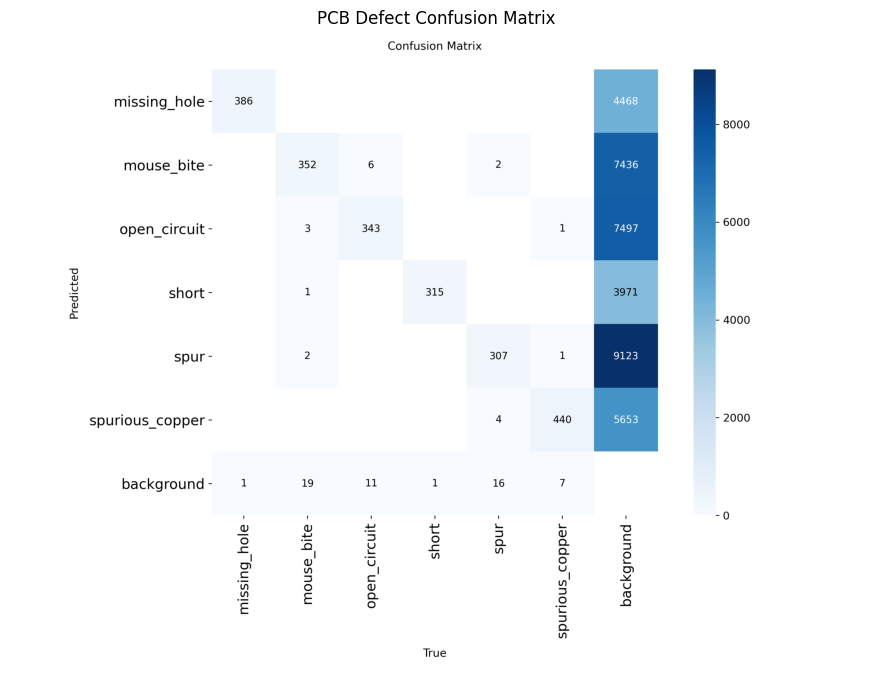

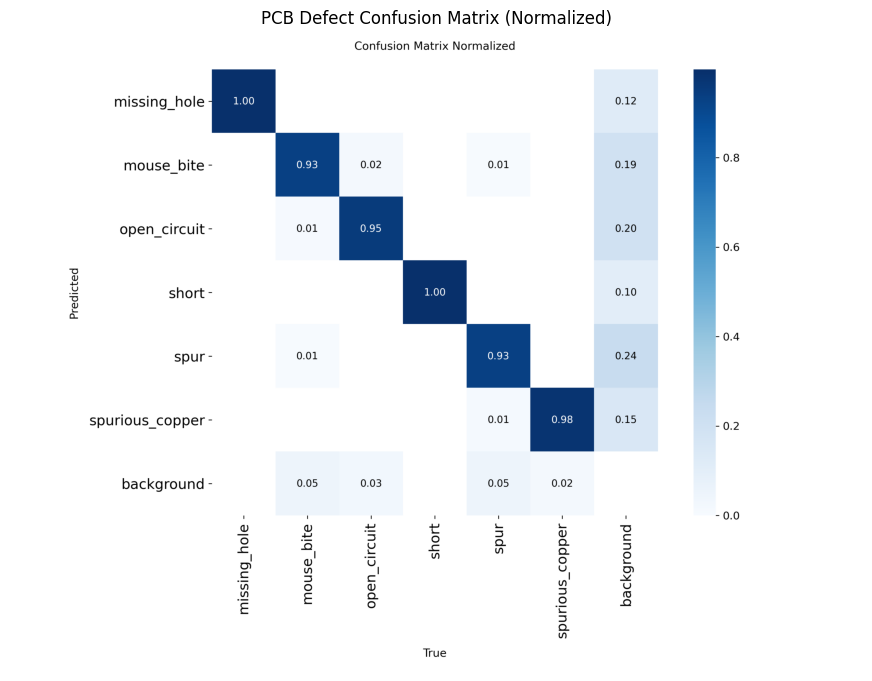

In [31]:
VAL_DIR = Path(val_metrics.save_dir)

# Raw counts and normalized versions (Ultralytics saves both)
cm_files = [
    ("confusion_matrix.png", "PCB Defect Confusion Matrix"),
    ("confusion_matrix_normalized.png", "PCB Defect Confusion Matrix (Normalized)"),
]

for file_name, title in cm_files:
    cm_path = VAL_DIR / file_name

    if cm_path.exists():
        img = cv2.imread(str(cm_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(11, 9))
        plt.imshow(img)
        plt.axis("off")
        plt.title(title)
        plt.show()
    else:
        print(f"{file_name} not found in {VAL_DIR}")

In [32]:
BASE_DIR = Path("/content/drive/MyDrive/PCB_Defect_Detection")   # edit this to your Drive folder

# Mount Drive if it isn't mounted already
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

DRIVE_WEIGHTS = BASE_DIR / "weights"
DRIVE_RESULTS = BASE_DIR / "results"

DRIVE_WEIGHTS.mkdir(parents=True, exist_ok=True)
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

# Save best and last models
shutil.copy2(BEST_MODEL_PATH, DRIVE_WEIGHTS / "pcb_yolo11s_best.pt")

if LAST_MODEL_PATH.exists():
    shutil.copy2(LAST_MODEL_PATH, DRIVE_WEIGHTS / "pcb_yolo11s_last.pt")

# Save training results
if RUN_DIR.exists():
    shutil.copytree(RUN_DIR, DRIVE_RESULTS / "yolo11s_baseline", dirs_exist_ok=True)

# Save validation results (confusion matrix, PR curves)
VAL_DIR = Path(val_metrics.save_dir)
if VAL_DIR.exists():
    shutil.copytree(VAL_DIR, DRIVE_RESULTS / "validation", dirs_exist_ok=True)

# Save the corrected dataset YAML
shutil.copy2(FIXED_YAML, BASE_DIR / "pcb_data.yaml")

print("Model and results saved to:", BASE_DIR)

Model and results saved to: /content/drive/MyDrive/PCB_Defect_Detection


In [33]:
MODEL_PATH = DRIVE_WEIGHTS / "pcb_yolo11s_best.pt"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

final_model = YOLO(str(MODEL_PATH))

print("Final trained model loaded from:", MODEL_PATH)
print("Classes:", final_model.names)

Final trained model loaded from: /content/drive/MyDrive/PCB_Defect_Detection/weights/pcb_yolo11s_best.pt
Classes: {0: 'missing_hole', 1: 'mouse_bite', 2: 'open_circuit', 3: 'short', 4: 'spur', 5: 'spurious_copper'}


In [34]:
TEST_IMAGE_DIR = DATASET_ROOT / "test" / "images"

if not TEST_IMAGE_DIR.exists():
    print("Test folder not found, using the validation images instead.")
    TEST_IMAGE_DIR = DATASET_ROOT / VAL_FOLDER / "images"

if not TEST_IMAGE_DIR.exists():
    raise FileNotFoundError(
        f"Image directory not found: {TEST_IMAGE_DIR}. "
        "Check the extracted dataset structure."
    )

test_images = sorted(
    p for p in TEST_IMAGE_DIR.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
)

if not test_images:
    raise FileNotFoundError(f"No images found in {TEST_IMAGE_DIR}")

print("Image directory:", TEST_IMAGE_DIR)
print("Number of test images:", len(test_images))

Image directory: /content/pcb_dataset/test/images
Number of test images: 189


In [35]:
CONFIDENCE_THRESHOLD = 0.25      # use 0.001 only when computing mAP
NMS_IOU_THRESHOLD = 0.7
IMAGE_SIZE = TRAIN_CONFIG["imgsz"]

predictions = final_model.predict(
    source=str(TEST_IMAGE_DIR),
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE_THRESHOLD,
    iou=NMS_IOU_THRESHOLD,
    max_det=300,
    device=TRAIN_CONFIG["device"],
    save=True,
    save_txt=True,            # also save YOLO-format predictions
    save_conf=True,           # include confidence in the .txt files
    project="/content/pcb_predictions",
    name="test_predictions",
    exist_ok=True,
    stream=True,              # processes images one by one, avoids RAM issues
    verbose=False
)

# With stream=True, results are generated lazily, so collect them here
predictions = list(predictions)

PRED_DIR = Path(predictions[0].save_dir)

print("Inference completed!")
print("Images processed:", len(predictions))
print("Total detections:", sum(len(r.boxes) for r in predictions))
print("Predictions saved to:", PRED_DIR)

Results saved to /content/pcb_predictions/test_predictions
99 labels saved to /content/pcb_predictions/test_predictions/labels
Inference completed!
Images processed: 189
Total detections: 264
Predictions saved to: /content/pcb_predictions/test_predictions


In [39]:
# Class names come from the model itself, so they can't drift from the training labels
import math

VALID_CLASSES = set(final_model.names.values())

CSV_COLUMNS = [
    "image_name", "class_name",
    "x_min", "y_min", "x_max", "y_max",
    "confidence"
]

prediction_rows = []
skipped = 0

for result in predictions:

    image_name = Path(result.path).name
    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        continue

    # Boxes are already in original image pixel coordinates
    xyxy = boxes.xyxy.cpu().numpy()
    class_ids = boxes.cls.cpu().numpy()
    scores = boxes.conf.cpu().numpy()

    original_h, original_w = result.orig_shape

    for bbox, class_id, score in zip(xyxy, class_ids, scores):

        x1, y1, x2, y2 = map(float, bbox)
        class_name = final_model.names[int(class_id)]

        if class_name not in VALID_CLASSES:
            raise ValueError(f"Unexpected class: {class_name}")

        if not all(map(math.isfinite, [x1, y1, x2, y2, score])):
            skipped += 1
            continue

        # Clamp to the original image dimensions
        x1 = max(0, min(x1, original_w))
        y1 = max(0, min(y1, original_h))
        x2 = max(0, min(x2, original_w))
        y2 = max(0, min(y2, original_h))

        if x2 <= x1 or y2 <= y1:
            skipped += 1
            continue

        prediction_rows.append({
            "image_name": image_name,
            "class_name": class_name,
            "x_min": int(round(x1)),
            "y_min": int(round(y1)),
            "x_max": int(round(x2)),
            "y_max": int(round(y2)),
            "confidence": round(float(score), 6)
        })

# Convert to DataFrame, highest confidence first within each image
submission_df = (
    pd.DataFrame(prediction_rows, columns=CSV_COLUMNS)
    .sort_values(["image_name", "confidence"], ascending=[True, False])
    .reset_index(drop=True)
)

# Save CSV
BASE_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = BASE_DIR / "predictions.csv"
submission_df.to_csv(CSV_PATH, index=False)

print("CSV generated successfully!")
print("Images with detections:", submission_df["image_name"].nunique(), "of", len(predictions))
print("Total detections:", len(submission_df))
print("Skipped invalid boxes:", skipped)
print("Output:", CSV_PATH)

display(submission_df.head(10))

CSV generated successfully!
Images with detections: 99 of 189
Total detections: 264
Skipped invalid boxes: 0
Output: /content/drive/MyDrive/PCB_Defect_Detection/predictions.csv


,image_name,class_name,x_min,y_min,x_max,y_max,confidence
0,01_missing_hole_09_jpg.rf.d7693f7fca88d8acaabd...,missing_hole,269,266,287,297,0.305741
1,01_missing_hole_09_jpg.rf.d7693f7fca88d8acaabd...,missing_hole,273,266,291,298,0.304386
2,01_missing_hole_09_jpg.rf.d7693f7fca88d8acaabd...,missing_hole,264,267,283,298,0.261578
3,01_missing_hole_15_jpg.rf.155026c2b1585f59c29d...,missing_hole,507,423,524,449,0.426544
4,01_missing_hole_15_jpg.rf.155026c2b1585f59c29d...,missing_hole,451,183,468,208,0.321890
5,01_missing_hole_15_jpg.rf.155026c2b1585f59c29d...,missing_hole,428,392,445,417,0.310753
6,01_short_14_jpg.rf.27e31a70f842f8be76c81664828...,short,236,124,263,145,0.274098
7,01_short_15_jpg.rf.db0f3e9e25b2de015f296d7193e...,short,359,448,379,485,0.462060
8,01_short_15_jpg.rf.db0f3e9e25b2de015f296d7193e...,short,107,362,122,387,0.312890
9,01_short_16_jpg.rf.eeab07d2418bd5ab880bce4fd69...,short,241,405,260,448,0.614822


In [40]:
df = pd.read_csv(CSV_PATH)

if df.empty:
    raise ValueError(f"{CSV_PATH} has no rows. Check the inference step and its confidence threshold.")

# Each check returns the rows that fail it
checks = {
    "Columns match CSV_COLUMNS": list(df.columns) == CSV_COLUMNS,
    "No missing values": not df.isna().any().any(),
    "All class names valid": df["class_name"].isin(VALID_CLASSES).all(),
    "Confidence between 0 and 1": df["confidence"].between(0, 1).all(),
    "x_min < x_max": (df["x_min"] < df["x_max"]).all(),
    "y_min < y_max": (df["y_min"] < df["y_max"]).all(),
    "Coordinates non-negative": (df[["x_min", "y_min", "x_max", "y_max"]] >= 0).all().all(),
}

for name, passed in checks.items():
    print(("PASS  " if passed else "FAIL  ") + name)

failed = [name for name, passed in checks.items() if not passed]

if failed:
    raise AssertionError(f"CSV validation failed: {failed}")

print("\nCSV validation passed!")
print("Total predictions:", len(df))
print("Unique images:", df["image_name"].nunique())

print("\nDetections by class:")
print(df["class_name"].value_counts())

print("\nConfidence summary:")
print(df["confidence"].describe().round(4))

print("\nCSV preview:")
display(df.head())

PASS  Columns match CSV_COLUMNS
PASS  No missing values
PASS  All class names valid
PASS  Confidence between 0 and 1
PASS  x_min < x_max
PASS  y_min < y_max
PASS  Coordinates non-negative

CSV validation passed!
Total predictions: 264
Unique images: 99

Detections by class:
class_name
short              87
missing_hole       55
spurious_copper    45
spur               37
mouse_bite         25
open_circuit       15
Name: count, dtype: int64

Confidence summary:
count    264.0000
mean       0.3702
std        0.1489
min        0.2508
25%        0.2798
50%        0.3091
75%        0.4007
max        0.8340
Name: confidence, dtype: float64

CSV preview:


,image_name,class_name,x_min,y_min,x_max,y_max,confidence
0,01_missing_hole_09_jpg.rf.d7693f7fca88d8acaabd...,missing_hole,269,266,287,297,0.305741
1,01_missing_hole_09_jpg.rf.d7693f7fca88d8acaabd...,missing_hole,273,266,291,298,0.304386
2,01_missing_hole_09_jpg.rf.d7693f7fca88d8acaabd...,missing_hole,264,267,283,298,0.261578
3,01_missing_hole_15_jpg.rf.155026c2b1585f59c29d...,missing_hole,507,423,524,449,0.426544
4,01_missing_hole_15_jpg.rf.155026c2b1585f59c29d...,missing_hole,451,183,468,208,0.321890


In [42]:
from google.colab import files

files.download(str(CSV_PATH))
print("Download started:", CSV_PATH.name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started: predictions.csv
